# 01. Data cleaning and quality checks

**Goal:** check the raw HR file, fix column names, flag impossible values, add bands, and save a clean file for the next notebooks and for Power BI.

**Input:** `data/raw/HR_Attrition_dataset.csv`  
**Output:** `data/processed/hr_attrition_clean.csv`

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from hr_utils import (load_raw, load_clean, rate_table, segment_table, plot_rate, savefig, save_table,
                      SEGMENT_FACTORS, PROCESSED, ACCENT, BASE)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

## 1. Load the raw file

In [2]:
raw = load_raw()
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (10000, 23)


,Employee_ID,Age,Attrition,Business_Travel,Department,Distance_From_Home,Education,Environment_Satisfaction,Gender,Salary,Job_Involvement,Job_Level,Job_Role,Job_Satisfaction,Marital_Status,Number_of_Companies_Worked_previously,Overtime,Salary_Hike_in_percent,Total_working_years_experience,Work_life_balance,No_of_years_worked_at_current_company,No_of_years_in_current_role,Years_since_last_promotion
0,1,56,Yes,Travel Rarely,Network Administration,24,Graduation,5,Male,186630,2,6,Manager,4,Married,7,Yes,85,9,1,7,2,4
1,2,46,Yes,Travel Rarely,Software Development,45,Degree,5,Male,78553,4,5,Help Desk,2,Divorced,3,No,22,18,4,1,2,0
2,3,32,No,No Travel,Data Science,30,Master's,3,Female,175003,1,4,HR,2,Single,2,Yes,100,0,4,5,5,8
3,4,60,Yes,Travel Frequently,Data Science,42,Graduation,2,Female,100795,2,8,Help Desk,3,Married,5,No,72,17,2,1,7,3
4,5,25,No,No Travel,Network Administration,26,Graduation,4,Female,75256,1,2,Director,4,Single,9,No,21,12,5,7,2,4


## 2. Quality checks

In [3]:
text_cols = raw.select_dtypes(exclude="number").columns.tolist()
checks = {
    "Rows": len(raw),
    "Columns": raw.shape[1],
    "Missing values": int(raw.isna().sum().sum()),
    "Duplicate rows": int(raw.duplicated().sum()),
    "Duplicate Employee_ID": int(raw["Employee_ID"].duplicated().sum()),
    "Text cells with extra spaces": int(sum((raw[c] != raw[c].str.strip()).sum() for c in text_cols)),
}
pd.Series(checks, name="result").to_frame()

,result
Rows,10000
Columns,23
Missing values,0
Duplicate rows,0
Duplicate Employee_ID,0
Text cells with extra spaces,0


In [4]:
for c in text_cols:
    print(f"{c}: {raw[c].value_counts().to_dict()}")

Attrition: {'No': 7753, 'Yes': 2247}
Business_Travel: {'Travel Rarely': 5988, 'Travel Frequently': 2014, 'No Travel': 1998}
Department: {'Cyber Security': 2080, 'Software Development': 2065, 'IT Services': 1957, 'Data Science': 1955, 'Network Administration': 1943}
Education: {'Graduation': 3066, 'Degree': 2994, "Master's": 1987, 'PhD': 978, 'Below College': 975}
Gender: {'Female': 5027, 'Male': 4973}
Job_Role: {'IT': 880, 'QA Analyst': 859, 'Business Analyst': 852, 'Manager': 846, 'Consultant': 840, 'Support': 826, 'HR': 825, 'Software Engineer': 825, 'Technician': 824, 'Director': 823, 'Developer': 822, 'Help Desk': 778}
Marital_Status: {'Married': 3391, 'Divorced': 3355, 'Single': 3254}
Overtime: {'No': 6949, 'Yes': 3051}


In [5]:
raw.describe().T[["min", "max", "mean"]].round(1)

,min,max,mean
Employee_ID,1.0,10000.0,5000.5
Age,18.0,63.0,40.5
Distance_From_Home,1.0,50.0,25.4
Environment_Satisfaction,1.0,5.0,3.0
Salary,30078.0,199989.0,114492.5
Job_Involvement,1.0,5.0,3.0
Job_Level,1.0,8.0,4.5
Job_Satisfaction,1.0,5.0,3.0
Number_of_Companies_Worked_previously,0.0,10.0,5.0
Salary_Hike_in_percent,0.0,100.0,50.1


**Result:** no missing values, no duplicate rows or IDs, no extra spaces, and every value is inside a valid range. The file does not need value cleaning.

The data looks **synthetic** (generated, not collected from a real company). The checks below show why.

In [6]:
print("Correlation of salary with job level:", round(raw["Salary"].corr(raw["Job_Level"]), 3))
print("Correlation of age with total experience:", round(raw["Age"].corr(raw["Total_working_years_experience"]), 3))
print()
print("Share of employees per department (%):")
print((raw["Department"].value_counts(normalize=True) * 100).round(1).to_string())

Correlation of salary with job level: 0.008
Correlation of age with total experience: -0.005

Share of employees per department (%):
Department
Cyber Security            20.8
Software Development      20.6
IT Services               19.6
Data Science              19.6
Network Administration    19.4


In a real company, salary rises with job level and experience rises with age. Here both correlations are about zero and every group has almost the same size. Findings in this project describe this dataset, not a real workforce.

## 3. Rename columns and create the target

Names are shortened to `snake_case`. The target `attrition_flag` is 1 when the employee left and 0 when the employee stayed.

The 1 to 5 scores (environment satisfaction, job involvement, job satisfaction, work-life balance) have no description in the file. They are treated as **1 = lowest and 5 = highest**. The attrition pattern supports this: higher scores go with lower attrition.

In [7]:
rename_map = {
    "Employee_ID": "employee_id", "Age": "age", "Attrition": "attrition",
    "Business_Travel": "business_travel", "Department": "department",
    "Distance_From_Home": "distance_from_home", "Education": "education",
    "Environment_Satisfaction": "environment_satisfaction", "Gender": "gender", "Salary": "salary",
    "Job_Involvement": "job_involvement", "Job_Level": "job_level", "Job_Role": "job_role",
    "Job_Satisfaction": "job_satisfaction", "Marital_Status": "marital_status",
    "Number_of_Companies_Worked_previously": "companies_worked_before", "Overtime": "overtime",
    "Salary_Hike_in_percent": "salary_hike_pct", "Total_working_years_experience": "total_experience_years",
    "Work_life_balance": "work_life_balance", "No_of_years_worked_at_current_company": "years_at_company",
    "No_of_years_in_current_role": "years_in_role", "Years_since_last_promotion": "years_since_promotion",
}
df = raw.rename(columns=rename_map).copy()

assert set(df["attrition"].unique()) == {"Yes", "No"}
df["attrition_flag"] = (df["attrition"] == "Yes").astype(int)

overall = df["attrition_flag"].mean() * 100
print(f"Overall attrition rate: {overall:.2f}% ({df['attrition_flag'].sum():,} of {len(df):,} employees)")

Overall attrition rate: 22.47% (2,247 of 10,000 employees)


## 4. Logical consistency checks

Some rows contain combinations that cannot happen, for example more years at the company than years of total work experience. These rows are **flagged, not deleted**, so the analysis stays transparent.

In [8]:
df["flag_tenure_gt_experience"] = (df["years_at_company"] > df["total_experience_years"]).astype(int)
df["flag_role_gt_tenure"] = (df["years_in_role"] > df["years_at_company"]).astype(int)
df["flag_promotion_gt_tenure"] = (df["years_since_promotion"] > df["years_at_company"]).astype(int)
df["flag_experience_gt_working_age"] = (df["total_experience_years"] > (df["age"] - 18)).astype(int)

flag_cols = [c for c in df.columns if c.startswith("flag_")]
df["any_data_issue"] = df[flag_cols].max(axis=1)

issues = pd.DataFrame({"rows_flagged": df[flag_cols].sum(), "pct_of_rows": (df[flag_cols].mean() * 100).round(1)})
issues.loc["any_data_issue"] = [df["any_data_issue"].sum(), round(df["any_data_issue"].mean() * 100, 1)]
issues

,rows_flagged,pct_of_rows
flag_tenure_gt_experience,2404.0,24.0
flag_role_gt_tenure,4590.0,45.9
flag_promotion_gt_tenure,3674.0,36.7
flag_experience_gt_working_age,2113.0,21.1
any_data_issue,8043.0,80.4


In [9]:
t = rate_table(df, "any_data_issue").set_index("any_data_issue")
print(f"Attrition rate: flagged rows {t.loc[1, 'attrition_rate_pct']}% vs other rows {t.loc[0, 'attrition_rate_pct']}%")
t

Attrition rate: flagged rows 22.23% vs other rows 23.45%


,employees,leavers,attrition_rate_pct,lift
any_data_issue,,,,
0,1957,459,23.45,1.04
1,8043,1788,22.23,0.99


In [10]:
display(Markdown(
    f"**{df['any_data_issue'].mean() * 100:.1f}% of rows** have at least one inconsistency, which is another sign that the data is synthetic. "
    f"Removing them would delete most of the file, so they are **kept and flagged** in the `flag_*` columns and in `any_data_issue`. "
    f"Flagged rows leave at about the same rate as the other rows ({t.loc[1, 'attrition_rate_pct']}% vs {t.loc[0, 'attrition_rate_pct']}%), "
    f"so the flags do not change the findings."))

**80.4% of rows** have at least one inconsistency, which is another sign that the data is synthetic. Removing them would delete most of the file, so they are **kept and flagged** in the `flag_*` columns and in `any_data_issue`. Flagged rows leave at about the same rate as the other rows (22.23% vs 23.45%), so the flags do not change the findings.

## 5. Employee_ID check

An ID number should not predict who leaves. This chart checks it.

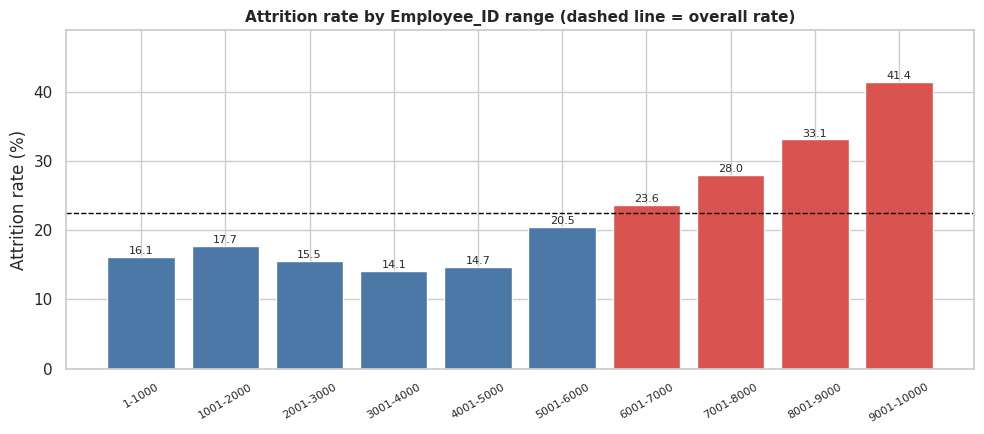

,id_range,employees,leavers,attrition_rate_pct,lift
0,1-1000,1000,161,16.1,0.72
1,1001-2000,1000,177,17.7,0.79
2,2001-3000,1000,155,15.5,0.69
3,3001-4000,1000,141,14.1,0.63
4,4001-5000,1000,147,14.7,0.65
5,5001-6000,1000,205,20.5,0.91
6,6001-7000,1000,236,23.6,1.05
7,7001-8000,1000,280,28.0,1.25
8,8001-9000,1000,331,33.1,1.47
9,9001-10000,1000,414,41.4,1.84


In [11]:
df["id_range"] = pd.cut(df["employee_id"], bins=range(0, 10001, 1000),
                        labels=[f"{i * 1000 + 1}-{(i + 1) * 1000}" for i in range(10)]).astype(str)
id_rates = rate_table(df, "id_range")

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_rate(ax, id_rates, "id_range", overall, "Attrition rate by Employee_ID range (dashed line = overall rate)", rotate=30)
fig.tight_layout()
savefig(fig, "01_attrition_by_employee_id_range")
plt.show()
id_rates

In [12]:
first = id_rates["attrition_rate_pct"].iloc[:5].mean()
last = id_rates["attrition_rate_pct"].iloc[-1]
display(Markdown(f"Attrition is about **{first:.1f}%** for the first 5,000 IDs and rises to **{last:.1f}%** for IDs 9,001 to 10,000."))
df = df.drop(columns=["id_range"])

Attrition is about **15.6%** for the first 5,000 IDs and rises to **41.4%** for IDs 9,001 to 10,000.

Attrition climbs steadily with the ID number, which has no business meaning. The file does not explain it, and years at the company show no matching pattern. It is treated as a **data artifact**: `employee_id` is kept only as a key and is **not used** in the analysis or the risk scorecard.

## 6. Add bands for analysis

Band labels start with a number so they sort correctly in charts and in Power BI. Salary and distance have no unit in the source file.

In [13]:
def band(series, edges, labels):
    return pd.cut(series, bins=edges, labels=labels, right=False).astype(str)

df["age_band"] = band(df["age"], [0, 25, 35, 45, 55, 200],
                      ["1. 18-24", "2. 25-34", "3. 35-44", "4. 45-54", "5. 55+"])
df["salary_band"] = band(df["salary"], [0, 60000, 90000, 120000, 150000, 10**9],
                         ["1. <60k", "2. 60k-90k", "3. 90k-120k", "4. 120k-150k", "5. 150k+"])
df["tenure_band"] = band(df["years_at_company"], [0, 2, 4, 6, 8, 100],
                         ["1. 0-1 yrs", "2. 2-3 yrs", "3. 4-5 yrs", "4. 6-7 yrs", "5. 8-10 yrs"])
df["distance_band"] = band(df["distance_from_home"], [0, 10, 20, 30, 40, 1000],
                           ["1. <10", "2. 10-19", "3. 20-29", "4. 30-39", "5. 40+"])
df["promotion_band"] = band(df["years_since_promotion"], [0, 2, 4, 6, 100],
                            ["1. 0-1 yrs", "2. 2-3 yrs", "3. 4-5 yrs", "4. 6-8 yrs"])
df["salary_hike_band"] = band(df["salary_hike_pct"], [0, 25, 50, 75, 1000],
                              ["1. 0-24%", "2. 25-49%", "3. 50-74%", "4. 75-100%"])

band_cols = ["age_band", "salary_band", "tenure_band", "distance_band", "promotion_band", "salary_hike_band"]
assert not df[band_cols].isin(["nan"]).any().any(), "some values fell outside the band edges"
df[band_cols].apply(lambda s: s.value_counts().sort_index().to_dict())

age_band            {'1. 18-24': 1469, '2. 25-34': 2200, '3. 35-44...
salary_band         {'1. <60k': 1775, '2. 60k-90k': 1816, '3. 90k-...
tenure_band         {'1. 0-1 yrs': 1873, '2. 2-3 yrs': 1789, '3. 4...
distance_band       {'1. <10': 1817, '2. 10-19': 1958, '3. 20-29':...
promotion_band      {'1. 0-1 yrs': 2242, '2. 2-3 yrs': 2215, '3. 4...
salary_hike_band    {'1. 0-24%': 2459, '2. 25-49%': 2432, '3. 50-7...
dtype: object

## 7. Save the clean file

In [14]:
PROCESSED.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED / "hr_attrition_clean.csv", index=False)
print("Saved:", PROCESSED / "hr_attrition_clean.csv")
print("Shape:", df.shape)
df.head()

Saved: /home/claude/hr/hr-attrition-analysis/data/processed/hr_attrition_clean.csv
Shape: (10000, 35)


,employee_id,age,attrition,business_travel,department,distance_from_home,education,environment_satisfaction,gender,salary,job_involvement,job_level,job_role,job_satisfaction,marital_status,companies_worked_before,overtime,salary_hike_pct,total_experience_years,work_life_balance,years_at_company,years_in_role,years_since_promotion,attrition_flag,flag_tenure_gt_experience,flag_role_gt_tenure,flag_promotion_gt_tenure,flag_experience_gt_working_age,any_data_issue,age_band,salary_band,tenure_band,distance_band,promotion_band,salary_hike_band
0,1,56,Yes,Travel Rarely,Network Administration,24,Graduation,5,Male,186630,2,6,Manager,4,Married,7,Yes,85,9,1,7,2,4,1,0,0,0,0,0,5. 55+,5. 150k+,4. 6-7 yrs,3. 20-29,3. 4-5 yrs,4. 75-100%
1,2,46,Yes,Travel Rarely,Software Development,45,Degree,5,Male,78553,4,5,Help Desk,2,Divorced,3,No,22,18,4,1,2,0,1,0,1,0,0,1,4. 45-54,2. 60k-90k,1. 0-1 yrs,5. 40+,1. 0-1 yrs,1. 0-24%
2,3,32,No,No Travel,Data Science,30,Master's,3,Female,175003,1,4,HR,2,Single,2,Yes,100,0,4,5,5,8,0,1,0,1,0,1,2. 25-34,5. 150k+,3. 4-5 yrs,4. 30-39,4. 6-8 yrs,4. 75-100%
3,4,60,Yes,Travel Frequently,Data Science,42,Graduation,2,Female,100795,2,8,Help Desk,3,Married,5,No,72,17,2,1,7,3,1,0,1,1,0,1,5. 55+,3. 90k-120k,1. 0-1 yrs,5. 40+,2. 2-3 yrs,3. 50-74%
4,5,25,No,No Travel,Network Administration,26,Graduation,4,Female,75256,1,2,Director,4,Single,9,No,21,12,5,7,2,4,0,0,0,0,1,1,2. 25-34,2. 60k-90k,4. 6-7 yrs,3. 20-29,3. 4-5 yrs,1. 0-24%
